# 03 - Pruebas y Predicciones
**Objetivo:** Cargar el modelo entrenado y ejecutar predicciones sobre imágenes personalizadas.

## Instrucciones:
1. Coloca tus imágenes (JPG/PNG) en la carpeta `data/test_images`
2. Ejecuta las celdas en orden
3. El cuaderno cargará el último modelo, redimensionará las imágenes a 32x32, aplicará la transformación y mostrará predicciones CIFAR-10

**Nota:** Este cuaderno NO entrena ni modifica el modelo.

In [3]:
import os
import glob
import joblib
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from utils.transform import transform_data_images, load_image_transformer

print('Librerías cargadas correctamente')


Librerías cargadas correctamente


## Cargar el modelo entrenado
Busca y carga el modelo más reciente en `models/` (excluye archivos de metadatos).

In [35]:
model_files = glob.glob('models/model_*.joblib')
model_files = [p for p in model_files if '_meta' not in os.path.basename(p)]
if not model_files:
    raise FileNotFoundError('No se encontró ningún modelo en models/. Ejecuta el cuaderno 02 primero.')

model_path = max(model_files, key=os.path.getmtime)
model_version = os.path.splitext(os.path.basename(model_path))[0].split('_')[-1]
print('Cargando modelo desde:', model_path)
model = joblib.load(model_path)
print(f'Modelo cargado exitosamente (versión {model_version})')
model


Cargando modelo desde: models\model_focus_1769391779.joblib
Modelo cargado exitosamente (versión 1769391779)


,hidden_layer_sizes,"(2048, ...)"
,activation,'relu'
,solver,'adam'
,alpha,1e-05
,batch_size,128
,learning_rate,'adaptive'
,learning_rate_init,0.0005
,power_t,0.5
,max_iter,1
,shuffle,True
,random_state,42


## Preparar carpeta para imágenes de prueba
Crea `data/test_images` si no existe. Coloca ahí tus imágenes para clasificar.

In [36]:
images_dir = 'data/test_images'
os.makedirs(images_dir, exist_ok=True)
print('📁 Coloca tus imágenes (jpg/png/bmp) en:', images_dir)
print('Total de archivos actuales:', len(glob.glob(os.path.join(images_dir, '*'))))

📁 Coloca tus imágenes (jpg/png/bmp) en: data/test_images
Total de archivos actuales: 10


## Cargar imágenes y ejecutar predicciones
Lee todas las imágenes de la carpeta, las preprocesa (redimensiona a 32x32 RGB, normaliza) y ejecuta predicciones.

Procesando 10 imágenes...

✅ Procesamiento completado: 10 imágenes



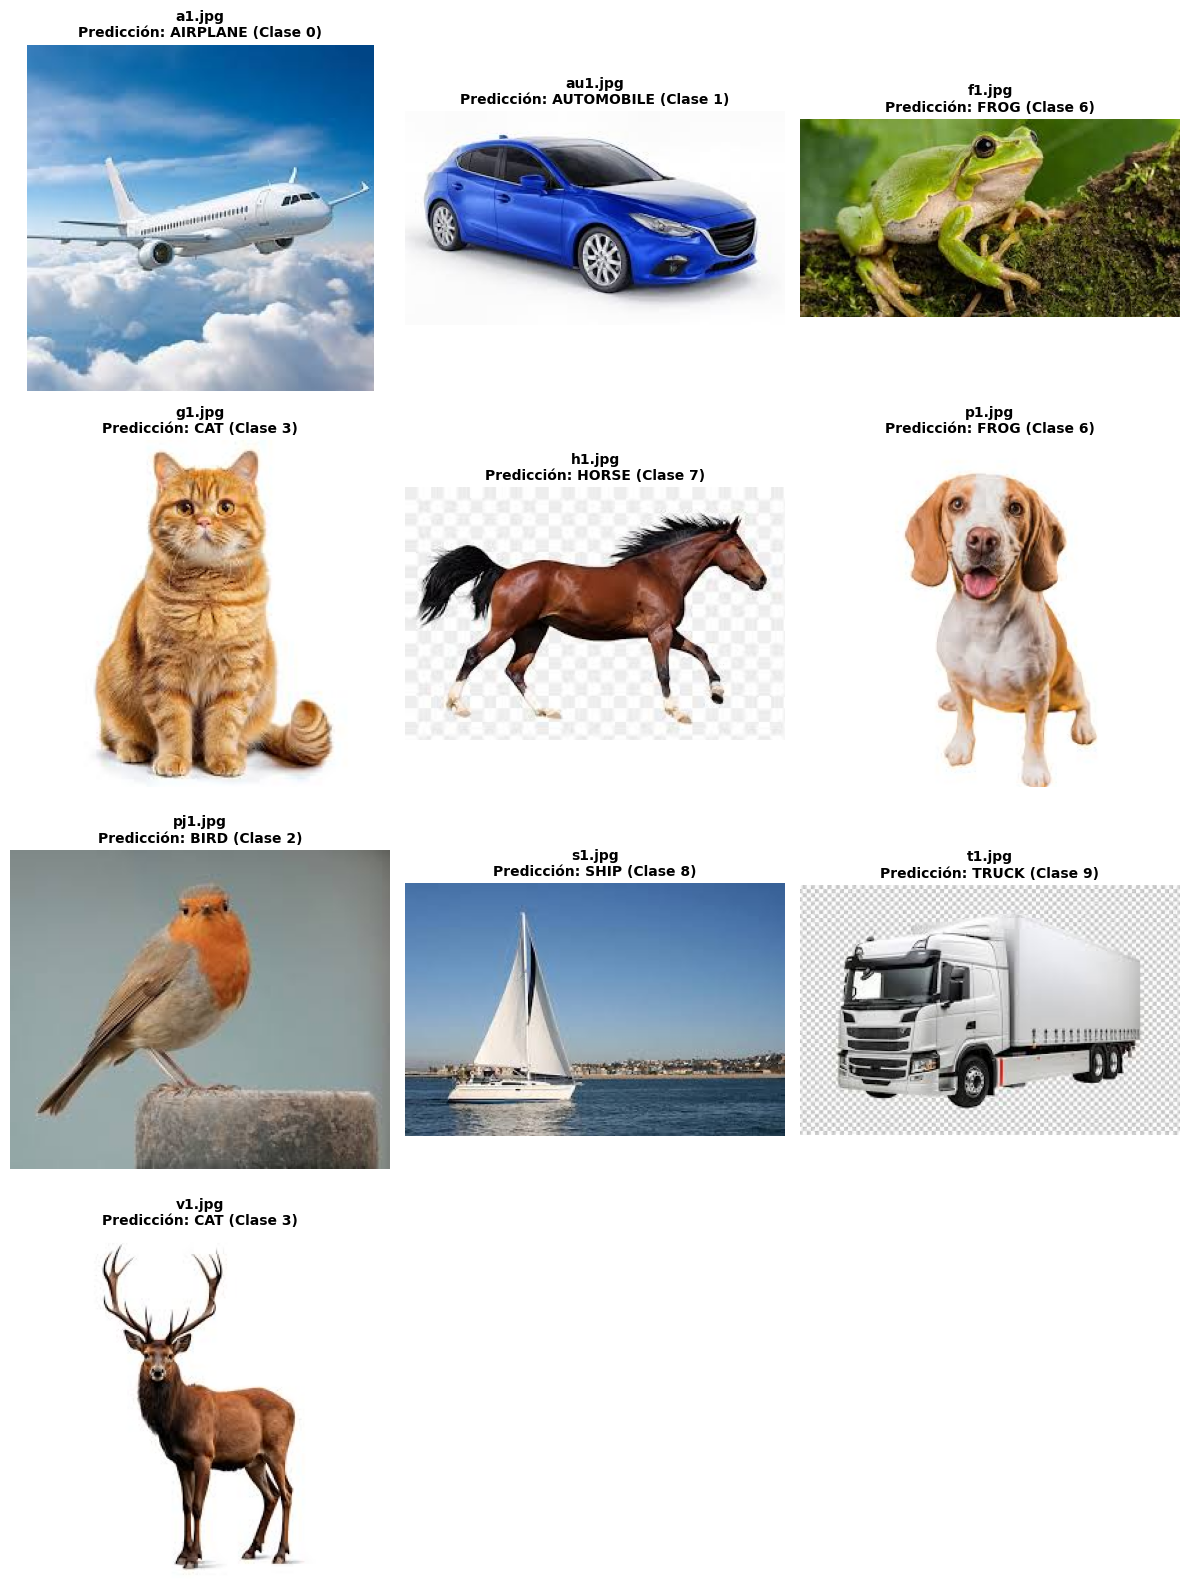

,file,pred_class,pred_label
0,a1.jpg,0,airplane
1,au1.jpg,1,automobile
2,f1.jpg,6,frog
3,g1.jpg,3,cat
4,h1.jpg,7,horse
5,p1.jpg,6,frog
6,pj1.jpg,2,bird
7,s1.jpg,8,ship
8,t1.jpg,9,truck
9,v1.jpg,3,cat


Resultados guardados en data/predictions_images.csv y data/predictions_images.npz


In [ ]:
exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
files = []
for e in exts:
    files.extend(glob.glob(os.path.join(images_dir, e)))
files = sorted(files)

if not files:
    print('⚠️  No se encontraron imágenes en', images_dir)
    print('Agrega archivos JPG/PNG y vuelve a ejecutar esta celda.')
else:
    imgs = []
    imgs_display = []
    names = []
    results = []
    print(f'Procesando {len(files)} imágenes...')
    
    for f in files:
        try:
            img_display = Image.open(f).convert('RGB')
            img = img_display.resize((32, 32), Image.BILINEAR)
            arr = np.array(img, dtype='float32')
            imgs.append(arr)
            imgs_display.append(img_display)
            names.append(os.path.basename(f))
        except Exception as e:
            print(f'Error cargando {os.path.basename(f)}: {e}')
    
    if imgs:
        X = np.stack(imgs, axis=0)
        
        try:
            tinfo = load_image_transformer()
            X_proc, _ = transform_data_images(
                X, y=None, 
                normalize=tinfo.get('normalize', True), 
                flatten=tinfo.get('flatten', True), 
                fit=False
            )
        except Exception as e:
            print('No se pudo cargar transformador guardado, usando normalización simple:', e)
            X_proc = X.astype('float32') / 255.0
            X_proc = X_proc.reshape((X_proc.shape[0], -1))
        
        y_pred = model.predict(X_proc)
        
        cifar_labels = {
            0: 'airplane', 1: 'automobile', 2: 'bird', 3: 'cat', 4: 'deer',
            5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'
        }
        
        print(f'\n✅ Procesamiento completado: {len(imgs)} imágenes\n')
        
        # Mostrar imágenes con predicciones
        cols = 3
        rows = (len(imgs) + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 4))
        if rows == 1:
            axes = axes.reshape(1, -1)
        axes = axes.flatten()
        
        for i, (img_display, name, pred) in enumerate(zip(imgs_display, names, y_pred)):
            label = cifar_labels.get(int(pred), 'unknown')
            axes[i].imshow(img_display)
            axes[i].axis('off')
            axes[i].set_title(f'{name}\nPredicción: {label.upper()} (Clase {int(pred)})', 
                            fontsize=10, fontweight='bold')
            results.append({'file': name, 'pred_class': int(pred), 'pred_label': label})
        
        # Ocultar ejes sobrantes
        for j in range(i + 1, len(axes)):
            axes[j].axis('off')
        
        plt.tight_layout()
        plt.show()


        if results:
            df_results = pd.DataFrame(results)
            display(df_results)
            os.makedirs('data', exist_ok=True)
            out_csv = 'data/predictions_images.csv'
            out_npz = 'data/predictions_images.npz'
            df_results.to_csv(out_csv, index=False)
            np.savez_compressed(out_npz, files=np.array(names), y_pred=y_pred)
            print('Resultados guardados en', out_csv, 'y', out_npz)


## Interpretación y consideraciones académicas

**Clases CIFAR-10:**
- 0: airplane, 1: automobile, 2: bird, 3: cat, 4: deer
- 5: dog, 6: frog, 7: horse, 8: ship, 9: truck

**Limitaciones:**
- El modelo fue entrenado con CIFAR-10 (imágenes de 32x32 de 10 clases específicas)
- Para clasificar otras categorías (animales/vehículos/personas), necesitarías:
  - Reentrenar con un dataset personalizado
  - Usar transfer learning desde un modelo preentrenado (ResNet, VGG, etc.)

**Recomendaciones para uso académico:**
- Analizar matriz de confusión sobre un conjunto de validación
- Calcular métricas: precisión, recall, F1-score por clase
- Documentar preprocesamiento y justificar arquitectura del modelo
- Considerar explicabilidad (SHAP, Grad-CAM) para interpretar predicciones